# 第 01 章　前置：卷积神经网络（CNN）怎么"看"图片

现代 VLM 的视觉部分多数用 Transformer（ViT），但**它的第一步仍是卷积**，而且很多"看图"的直觉（边缘 → 纹理 → 部件 → 物体）都来自 CNN。本章分四步：

1. **手工卷积核**：用人设计的卷积核处理照片，看它提取出边缘
2. **手写卷积**：自己用 `unfold`（im2col）+ 矩阵乘法实现卷积，验证与 `F.conv2d` 一致
3. **训练一个小 CNN**：在 Mac GPU 上从零训练分类器识别圆形、方形、三角形，看它**自己学出**什么卷积核
4. **预训练 ResNet-18**：看照片流过 18 层网络时每一层变成什么，并用 CAM 看它"盯着哪里"

最后一节把卷积和下一章的 ViT 连起来。

In [1]:
import sys, pathlib  # 导入路径工具
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "vlmlab").exists())  # 向上找到项目根目录
sys.path.insert(0, str(ROOT))  # 让 Python 能导入 vlmlab

import math, time  # 数学与计时
import numpy as np  # 数组
import torch  # PyTorch
import torch.nn as nn  # 网络层
import torch.nn.functional as F  # 函数式接口
import matplotlib.pyplot as plt  # 绘图
from PIL import Image, ImageDraw  # 画图形用
from vlmlab import (setup_matplotlib, seed_everything, get_device, load_photo, show_images,  # 基础工具
                    feature_maps, kernels_rgb, overlay, pca_rgb, normalize01, ActivationCache, check_close)  # 可视化与检验工具

setup_matplotlib()  # 中文字体
seed_everything(0)  # 固定随机种子
device = get_device()  # mps
photo = load_photo().resize((384, 288))  # 读入照片并缩小，便于演示
x = torch.from_numpy(np.asarray(photo).copy()).permute(2, 0, 1).float() / 255  # PIL → [3,H,W] 的 0~1 张量（第 00 章学过）
gray = x.mean(0, keepdim=True)  # 灰度图 [1,H,W]：三个通道取平均
print("彩色:", tuple(x.shape), " 灰度:", tuple(gray.shape))  # 打印形状

彩色: (3, 288, 384)  灰度: (1, 288, 384)


## 1. 卷积是什么：一个小窗口在图上滑动

一个 3×3 的**卷积核**（也叫滤波器）是 9 个数字。把它放到图片的每个位置，和下面的 3×3 像素**逐个相乘再相加**，得到一个输出像素。从左到右、从上到下滑一遍，就得到一张新的图（**特征图**）。

卷积核里的数字决定"找什么"。下面是几个人工设计的经典卷积核：

输入: (1, 1, 288, 384) → 输出: (1, 4, 288, 384)


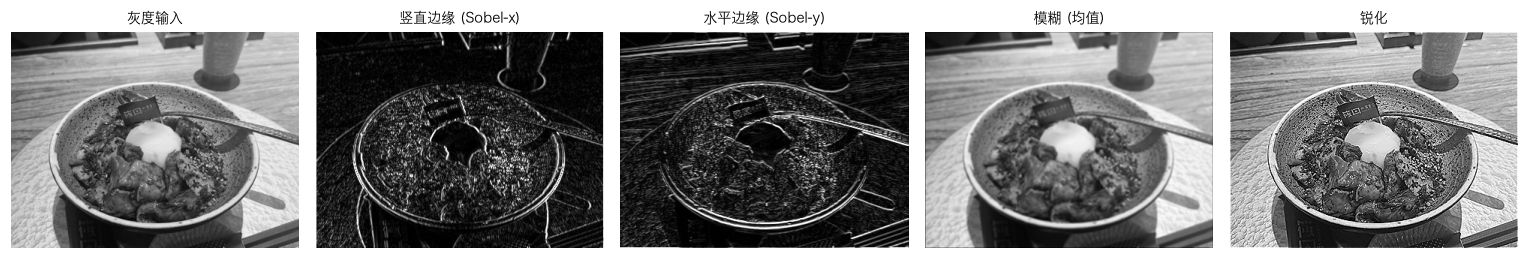

In [2]:
kernels = {  # 名字 → 3×3 卷积核
    "竖直边缘 (Sobel-x)": [[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]],  # 左右亮度差大的地方响应强
    "水平边缘 (Sobel-y)": [[-1, -2, -1], [0, 0, 0], [1, 2, 1]],  # 上下亮度差大的地方响应强
    "模糊 (均值)": [[1 / 9] * 3] * 3,  # 9 个像素取平均
    "锐化": [[0, -1, 0], [-1, 5, -1], [0, -1, 0]],  # 中心加强、四周减弱
}
weight = torch.tensor(list(kernels.values()), dtype=torch.float32)  # [4,3,3]：4 个卷积核
weight = weight.unsqueeze(1)  # [4,1,3,3]：F.conv2d 要求 [输出通道, 输入通道, 高, 宽]
out = F.conv2d(gray.unsqueeze(0), weight, padding=1)  # 输入 [1,1,H,W]，padding=1 让输出尺寸不变
print("输入:", tuple(gray.unsqueeze(0).shape), "→ 输出:", tuple(out.shape))  # 1 个通道进，4 个通道出
shown = [o.abs() / o.abs().quantile(0.99) if i < 2 else o for i, o in enumerate(out[0])]  # 边缘图取绝对值，再除以 99% 分位数，让少数极亮的点不至于把其他边缘压暗
show_images([gray[0]] + [t.clamp(0, 1) for t in shown],  # 全部裁剪到 0~1 再显示
            titles=["灰度输入"] + list(kernels.keys()), cmap="gray", size=2.8)  # 标题和色图

**观察**：竖直边缘核让碗的左右边缘、筷子变亮；水平边缘核让桌子木纹和碗的上下沿变亮。**同一张图，不同的卷积核，提取出不同的信息。**

CNN 的核心思想：**卷积核里的数字不靠人设计，让网络自己从数据里学。**

## 2. 手写卷积：卷积 = 切小块 + 矩阵乘法

卷积可以拆成两步：
1. **im2col**：把每个位置的 3×3 小窗口拉直成一个 9 维向量（彩色图则是 3×3×3=27 维）。PyTorch 的 `F.unfold` 就做这件事
2. **矩阵乘法**：用卷积核（也拉直）和所有小窗口做点积

这个视角很关键，**第 03 章 ViT 的 patch embedding 就是一个"窗口不重叠"的卷积**。

In [3]:
def my_conv2d(img, w, b=None, stride=1, padding=0):  # 自己实现的卷积；img:[B,Cin,H,W]，w:[Cout,Cin,k,k]
    B, Cin, H, W = img.shape  # 输入形状
    Cout, _, k, _ = w.shape  # 卷积核形状
    cols = F.unfold(img, kernel_size=k, stride=stride, padding=padding)  # [B, Cin*k*k, L]：L 是窗口个数
    out = w.reshape(Cout, -1) @ cols  # [Cout, Cin*k*k] @ [B, Cin*k*k, L] → [B, Cout, L]
    if b is not None:  # 有偏置就加上
        out = out + b.view(1, -1, 1)  # 广播到每个位置
    Ho = (H + 2 * padding - k) // stride + 1  # 输出高度公式
    Wo = (W + 2 * padding - k) // stride + 1  # 输出宽度公式
    return out.reshape(B, Cout, Ho, Wo)  # 排回图片形状

cols = F.unfold(x.unsqueeze(0), kernel_size=3, padding=1)  # 看看 unfold 的输出
print("unfold 输出形状:", tuple(cols.shape), "= [batch, 3通道×3×3, 窗口数 H×W]")  # 27 维 × 110592 个窗口
w_rand = torch.randn(8, 3, 3, 3)  # 随机 8 个彩色卷积核
b_rand = torch.randn(8)  # 随机偏置
for stride, padding in [(1, 1), (2, 1), (1, 0)]:  # 试几种步长和填充
    mine = my_conv2d(x.unsqueeze(0), w_rand, b_rand, stride, padding)  # 手写版
    ref = F.conv2d(x.unsqueeze(0), w_rand, b_rand, stride=stride, padding=padding)  # 官方版
    check_close(f"stride={stride}, padding={padding}", mine, ref, atol=1e-4)  # 对比

unfold 输出形状: (1, 27, 110592) = [batch, 3通道×3×3, 窗口数 H×W]
✅ stride=1, padding=1: 形状 (1, 8, 288, 384)，最大误差 2.86e-06（容差 1e-04）
✅ stride=2, padding=1: 形状 (1, 8, 144, 192)，最大误差 2.38e-06（容差 1e-04）
✅ stride=1, padding=0: 形状 (1, 8, 286, 382)，最大误差 2.86e-06（容差 1e-04）


**输出尺寸公式**：$H_{out} = \lfloor (H + 2 \cdot padding - k) / stride \rfloor + 1$

- `stride=2`：窗口每次跳 2 格，输出长宽减半
- `padding=1`：四周补一圈 0，3×3 卷积后尺寸不变
- **池化**（MaxPool）：在窗口里取最大值，没有参数，也用于缩小尺寸

下面把同一个边缘检测核连续用几次 stride=2 的卷积，再看池化，感受分辨率的变化。

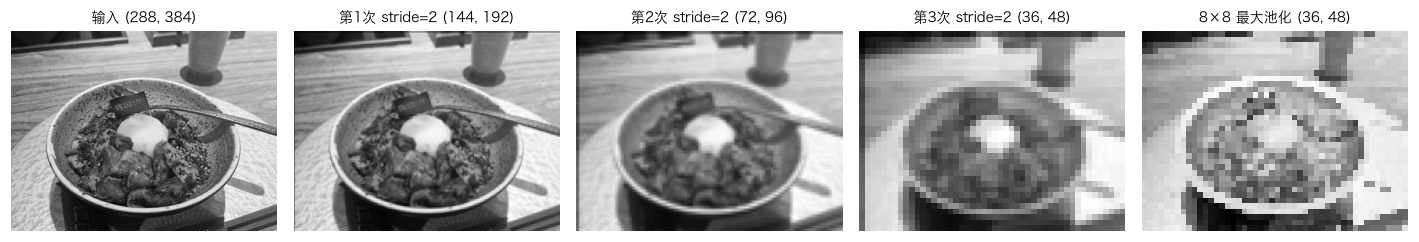

In [4]:
imgs, titles = [gray[0]], [f"输入 {tuple(gray.shape[1:])}"]  # 收集要显示的图
cur = gray.unsqueeze(0)  # [1,1,H,W]
for i in range(3):  # 连续 3 次
    cur = F.conv2d(cur, weight[2:3], stride=2, padding=1)  # 用"模糊"核、步长 2
    imgs.append(cur[0, 0])  # 记录
    titles.append(f"第{i+1}次 stride=2 {tuple(cur.shape[2:])}")  # 标题含尺寸
pooled = F.max_pool2d(gray.unsqueeze(0), kernel_size=8)  # 8×8 最大池化
imgs.append(pooled[0, 0])  # 记录
titles.append(f"8×8 最大池化 {tuple(pooled.shape[2:])}")  # 标题
show_images(imgs, titles=titles, cmap="gray", size=2.6)  # 显示

## 3. 从零训练一个小 CNN

现在让网络自己学卷积核。任务：识别 64×64 图片里是**圆形、方形还是三角形**（颜色、大小、位置、背景都随机）。数据集用代码现场生成，不用下载。

这一节会用到 PyTorch 训练的标准组件：`Dataset` → `DataLoader` → 模型 → 损失函数 → 优化器 → 训练循环。

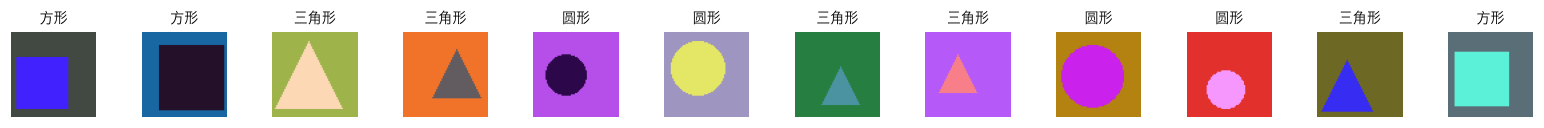

In [5]:
CLASSES = ["圆形", "方形", "三角形"]  # 三个类别

def make_shape(label, rng):  # 生成一张 64×64 的随机图形
    bg = tuple(int(v) for v in rng.integers(0, 256, 3))  # 随机背景色
    fg = tuple(int(v) for v in rng.integers(0, 256, 3))  # 随机前景色
    while sum(abs(a - b) for a, b in zip(bg, fg)) < 150:  # 前景和背景太像就重新选
        fg = tuple(int(v) for v in rng.integers(0, 256, 3))  # 重新随机
    img = Image.new("RGB", (64, 64), bg)  # 新建画布
    d = ImageDraw.Draw(img)  # 画笔
    s = int(rng.integers(14, 26))  # 半径/半边长
    cx, cy = (int(v) for v in rng.integers(s + 2, 64 - s - 2, 2))  # 随机中心，保证不出界
    if label == 0:  # 圆
        d.ellipse([cx - s, cy - s, cx + s, cy + s], fill=fg)  # 画圆
    elif label == 1:  # 方
        d.rectangle([cx - s, cy - s, cx + s, cy + s], fill=fg)  # 画正方形
    else:  # 三角形
        d.polygon([(cx, cy - s), (cx - s, cy + s), (cx + s, cy + s)], fill=fg)  # 画三角形
    return img  # 返回 PIL 图

class ShapeDataset(torch.utils.data.Dataset):  # 自定义数据集：必须实现 __len__ 和 __getitem__
    def __init__(self, n, seed):  # n 张图，seed 控制随机性
        rng = np.random.default_rng(seed)  # 独立的随机数生成器
        self.labels = rng.integers(0, 3, n)  # 每张图的类别
        imgs = [np.asarray(make_shape(int(l), rng)) for l in self.labels]  # 一次性生成全部图片
        self.x = torch.from_numpy(np.stack(imgs)).permute(0, 3, 1, 2).float() / 255  # [n,3,64,64]
        self.y = torch.from_numpy(self.labels).long()  # 类别标签，long 类型

    def __len__(self):  # 数据集大小
        return len(self.y)  # 图片数

    def __getitem__(self, i):  # 取第 i 个样本
        return self.x[i], self.y[i]  # (图片, 标签)

train_set, test_set = ShapeDataset(4000, seed=1), ShapeDataset(800, seed=2)  # 训练集和测试集用不同种子
train_loader = torch.utils.data.DataLoader(train_set, batch_size=64, shuffle=True)  # 每次取 64 张，打乱顺序
test_loader = torch.utils.data.DataLoader(test_set, batch_size=256)  # 测试不用打乱
show_images([train_set[i][0] for i in range(12)], titles=[CLASSES[int(train_set[i][1])] for i in range(12)], cols=12, size=1.2)  # 看看数据长什么样

网络结构：三层"卷积 → BatchNorm → ReLU"，前两层后接池化，最后全局平均池化 + 线性分类头。参数约 1.5 万个。

**为什么要 BatchNorm？** 本教程第一版没有 BatchNorm，训练后 conv1 的 16 个通道里有 **15 个"死"了**：ReLU 之后恒为 0。这叫 *dying ReLU*，即某个通道的输出一直是负数，梯度为 0，就再也学不动了。BatchNorm 把每个通道的输出标准化到均值 0、方差 1 附近，大大缓解了这个问题，训练也更快。另外，输入也像第 00 章那样归一化到 -1~1。

In [6]:
class SmallCNN(nn.Module):  # 小型卷积网络
    def __init__(self):  # 声明层
        super().__init__()  # 父类初始化
        self.conv1 = nn.Conv2d(3, 16, kernel_size=5, padding=2)  # 3→16 通道，5×5 卷积核（大一点方便看）
        self.bn1 = nn.BatchNorm2d(16)  # 对 16 个通道分别做标准化
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)  # 16→32 通道
        self.bn2 = nn.BatchNorm2d(32)  # 标准化
        self.conv3 = nn.Conv2d(32, 32, kernel_size=3, padding=1)  # 32→32 通道
        self.bn3 = nn.BatchNorm2d(32)  # 标准化
        self.head = nn.Linear(32, 3)  # 分类头：32 维 → 3 类

    def forward(self, x):  # 前向
        x = (x - 0.5) / 0.5  # 输入归一化到 -1~1
        x = F.max_pool2d(F.relu(self.bn1(self.conv1(x))), 2)  # 卷积 → BN → ReLU → 池化：[B,16,32,32]
        x = F.max_pool2d(F.relu(self.bn2(self.conv2(x))), 2)  # [B,32,16,16]
        x = F.relu(self.bn3(self.conv3(x)))  # [B,32,16,16]
        return self.head(x.mean(dim=(2, 3)))  # 全局平均池化 → [B,32] → [B,3]

model = SmallCNN().to(device)  # 建模型并放到 GPU
print("参数量:", sum(p.numel() for p in model.parameters()))  # 统计参数
kernels_before = model.conv1.weight.detach().cpu().clone()  # 保存训练前的卷积核，稍后对比

参数量: 15363


第 1 轮  损失 1.011  测试准确率 49.0%


第 2 轮  损失 0.471  测试准确率 99.9%


第 3 轮  损失 0.125  测试准确率 99.8%


第 4 轮  损失 0.062  测试准确率 100.0%


第 5 轮  损失 0.039  测试准确率 100.0%


第 6 轮  损失 0.029  测试准确率 100.0%


第 7 轮  损失 0.027  测试准确率 100.0%


第 8 轮  损失 0.025  测试准确率 100.0%
训练用时 8.0 秒（设备：mps）


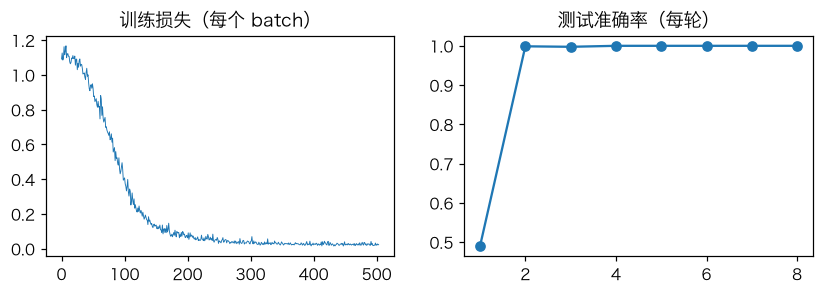

In [7]:
def evaluate(m):  # 计算测试集准确率
    m.eval()  # 推理模式
    correct = 0  # 正确数
    with torch.no_grad():  # 不需要梯度
        for xb, yb in test_loader:  # 遍历测试集
            correct += (m(xb.to(device)).argmax(1).cpu() == yb).sum().item()  # argmax 取分数最高的类别
    m.train()  # 切回训练模式
    return correct / len(test_set)  # 准确率

EPOCHS = 8  # 训练轮数
opt = torch.optim.Adam(model.parameters(), lr=2e-3)  # Adam 优化器，比 SGD 收敛更快
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=EPOCHS * len(train_loader))  # 学习率按余弦曲线从 2e-3 逐渐降到 0，后期更稳
history = {"loss": [], "acc": []}  # 记录训练过程
t0 = time.time()  # 计时
for epoch in range(EPOCHS):  # 逐轮训练
    for xb, yb in train_loader:  # 每次一个 batch
        xb, yb = xb.to(device), yb.to(device)  # 搬到 GPU
        loss = F.cross_entropy(model(xb), yb)  # 交叉熵损失：分类任务的标准损失
        opt.zero_grad()  # 清空旧梯度
        loss.backward()  # 反向传播
        opt.step()  # 更新参数
        sched.step()  # 更新学习率
        history["loss"].append(loss.item())  # 记录损失
    history["acc"].append(evaluate(model))  # 每轮结束测一次准确率
    print(f"第 {epoch+1} 轮  损失 {np.mean(history['loss'][-63:]):.3f}  测试准确率 {history['acc'][-1]:.1%}")  # 打印
print(f"训练用时 {time.time()-t0:.1f} 秒（设备：{device}）")  # 总时间

fig, axes = plt.subplots(1, 2, figsize=(9, 2.6))  # 两个子图
axes[0].plot(history["loss"], lw=0.6)  # 损失曲线
axes[0].set_title("训练损失（每个 batch）")  # 标题
axes[1].plot(range(1, EPOCHS + 1), history["acc"], "o-")  # 准确率曲线
axes[1].set_title("测试准确率（每轮）")  # 标题
plt.show()  # 显示

### 网络学到了什么卷积核？
上面是随机初始化的 16 个 5×5 彩色卷积核，下面是训练后的。

说实话，**直接看卷积核很难看出门道**：训练数据里图形的颜色是随机的，网络要学的是"和颜色无关的形状边界"，所以卷积核在 RGB 上看起来像彩色噪声。更好的办法是看它们的**输出**（下一节），每个通道各自负责某个方向的边缘。

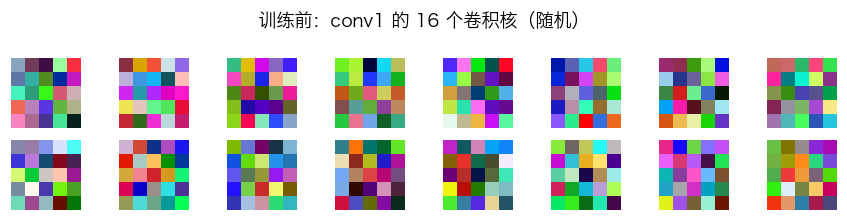

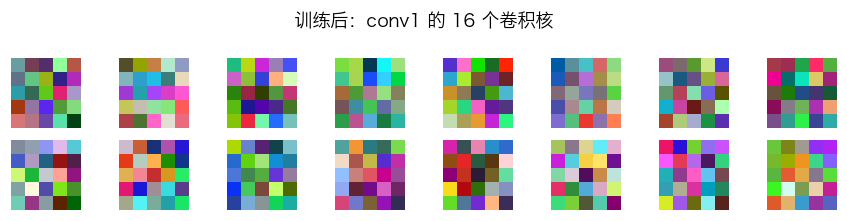

In [8]:
kernels_rgb(kernels_before, n=16, cols=8, title="训练前：conv1 的 16 个卷积核（随机）", size=1.0)  # 训练前
kernels_rgb(model.conv1.weight, n=16, cols=8, title="训练后：conv1 的 16 个卷积核", size=1.0)  # 训练后

### 一张图流过网络：每层变成了什么

真实类别: 圆形  预测概率: {'圆形': '99.3%', '方形': '0.2%', '三角形': '0.5%'}


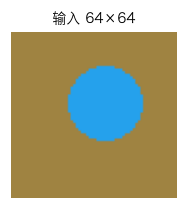

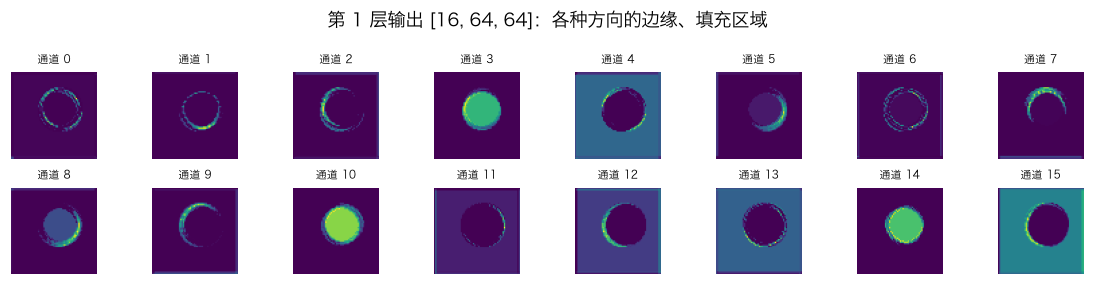

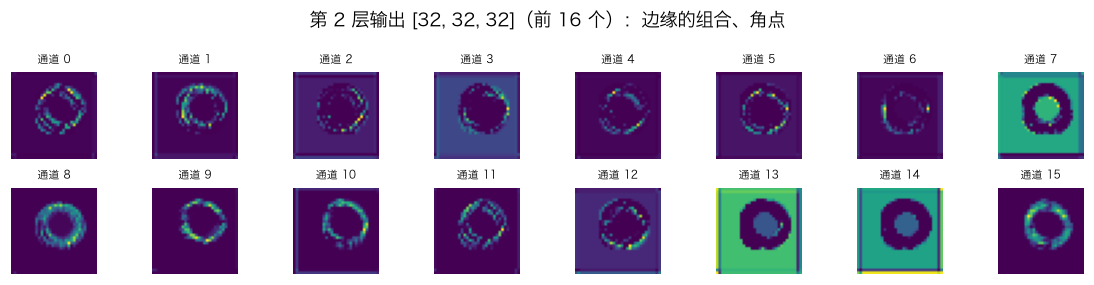

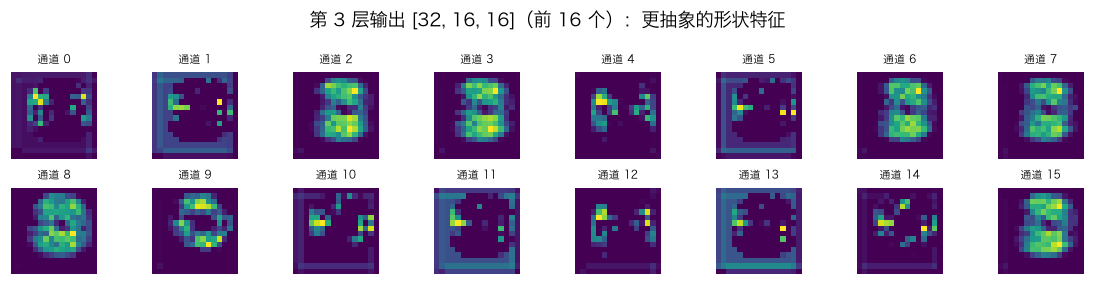

第 1 层 16 个通道中有输出（非全 0）的通道数: 16


In [9]:
sample, label = test_set[3]  # 取一张测试图
model.eval()  # 推理模式：BatchNorm 使用训练时累计的均值和方差
with ActivationCache(model, ["bn1", "bn2", "bn3"]) as cache:  # 观察三层 BN 的输出（ReLU 之前）
    with torch.no_grad():  # 不需要梯度
        logits = model(sample[None].to(device))  # 前向，[None] 等价于 unsqueeze(0)
prob = logits.softmax(-1)[0].cpu()  # softmax 把分数变成概率
print("真实类别:", CLASSES[int(label)], " 预测概率:", {c: f"{p:.1%}" for c, p in zip(CLASSES, prob)})  # 打印
show_images([sample], titles=["输入 64×64"], size=2)  # 输入图
feature_maps(F.relu(cache["bn1"][0]), n=16, cols=8, title="第 1 层输出 [16, 64, 64]：各种方向的边缘、填充区域", size=1.3)  # 第一层：边缘
feature_maps(F.relu(cache["bn2"][0]), n=16, cols=8, title="第 2 层输出 [32, 32, 32]（前 16 个）：边缘的组合、角点", size=1.3)  # 第二层：组合
feature_maps(F.relu(cache["bn3"][0]), n=16, cols=8, title="第 3 层输出 [32, 16, 16]（前 16 个）：更抽象的形状特征", size=1.3)  # 第三层：抽象
print("第 1 层 16 个通道中有输出（非全 0）的通道数:", int((F.relu(cache["bn1"][0]).amax((1, 2)) > 0).sum()))  # 检查有没有"死"通道

## 4. 预训练 ResNet-18：真实照片流过 18 层

小 CNN 只认识三种图形。ResNet-18 在 ImageNet（120 万张图、1000 类）上训练过，结构是：

```
conv1(7×7, stride 2) → maxpool → layer1 → layer2 → layer3 → layer4 → 全局平均池化 → fc(1000 类)
  [64,112,112]          [64,56,56] [64,56,56] [128,28,28] [256,14,14] [512,7,7]
```

规律：**越往后，分辨率越低，通道数越多**。空间信息被逐步"浓缩"成语义信息。

首次运行会下载约 45 MB 的权重到 `models/torch_hub/`。

In [10]:
import torchvision  # PyTorch 官方视觉库
torch.hub.set_dir(str(ROOT / "models" / "torch_hub"))  # 权重下载到项目目录
weights = torchvision.models.ResNet18_Weights.IMAGENET1K_V1  # 选择 ImageNet 预训练权重
resnet = torchvision.models.resnet18(weights=weights).to(device).eval()  # 构建模型并加载权重
preprocess = weights.transforms()  # 该权重对应的官方预处理：缩放、中心裁剪 224、归一化
inp = preprocess(load_photo()).unsqueeze(0).to(device)  # 原始照片 → [1,3,224,224]
print("ResNet 输入:", tuple(inp.shape))  # 打印
layers = ["conv1", "layer1", "layer2", "layer3", "layer4"]  # 要观察的层
with ActivationCache(resnet, layers) as cache:  # 挂钩子
    with torch.no_grad():  # 推理
        logits = resnet(inp)  # 前向
for name in layers:  # 打印每层形状
    print(f"{name:7s} 输出 {tuple(cache[name].shape)}")  # [1, C, H, W]

ResNet 输入: (1, 3, 224, 224)
conv1   输出 (1, 64, 112, 112)
layer1  输出 (1, 64, 56, 56)
layer2  输出 (1, 128, 28, 28)
layer3  输出 (1, 256, 14, 14)
layer4  输出 (1, 512, 7, 7)


### 每一层的特征图
每层挑 8 个通道显示。注意分辨率从 112 降到 7。

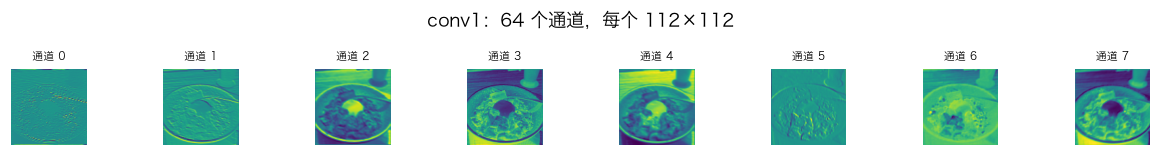

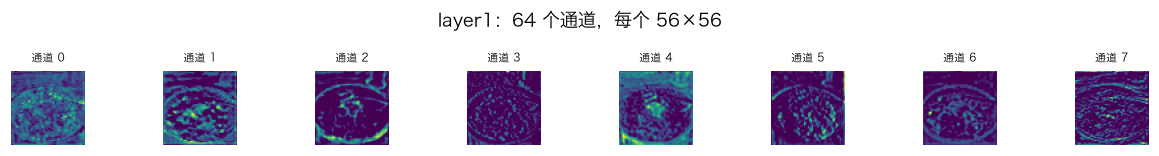

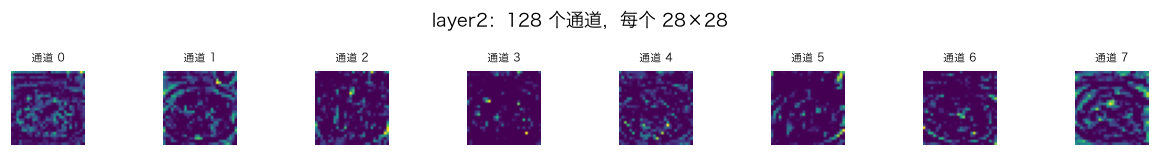

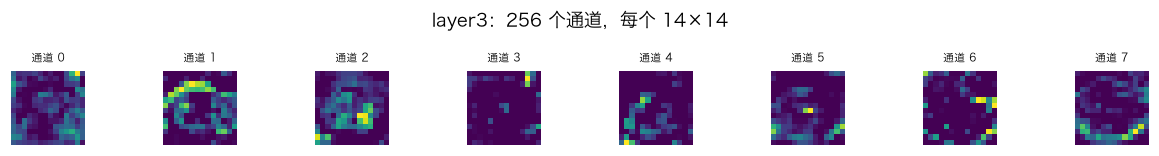

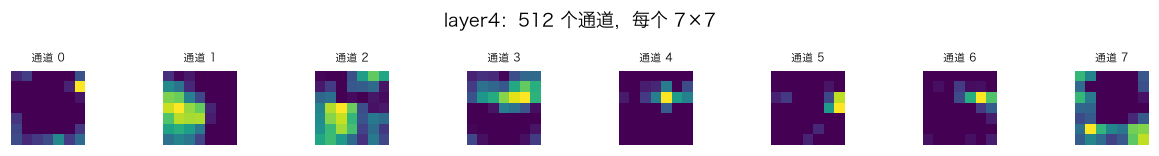

In [11]:
for name in layers:  # 逐层
    fm = cache[name][0]  # [C,H,W]
    feature_maps(fm, n=8, cols=8, title=f"{name}：{fm.shape[0]} 个通道，每个 {fm.shape[1]}×{fm.shape[2]}", size=1.4)  # 显示前 8 个通道

### 用 PCA 给特征"上色"
一层有几十到几百个通道，逐个看不过来。把每个位置的 C 维特征向量用 PCA 压成 3 维当 RGB：**颜色相近 = 网络认为这两个位置"相似"**。后面看 ViT 和 VLM 时也一直用这个方法。

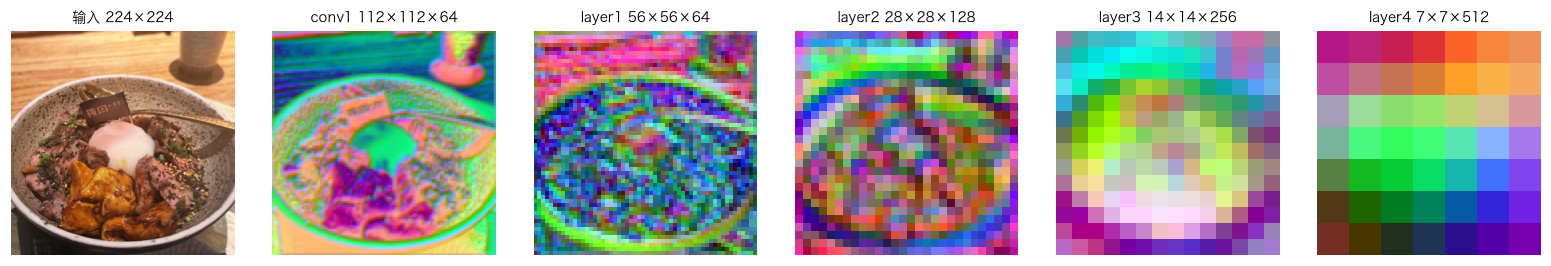

In [12]:
shown = [inp[0].cpu() * torch.tensor(weights.transforms().std).view(3, 1, 1) + torch.tensor(weights.transforms().mean).view(3, 1, 1)]  # 反归一化后的输入图
titles = ["输入 224×224"]  # 标题
for name in layers:  # 逐层
    fm = cache[name][0]  # [C,H,W]
    C, h, w = fm.shape  # 拆形状
    shown.append(pca_rgb(fm.flatten(1).T, hw=(h, w)))  # [H*W, C] → PCA → [h,w,3]
    titles.append(f"{name} {h}×{w}×{C}")  # 标题
show_images(shown, titles=titles, size=2.4)  # 显示

**观察**：浅层（conv1、layer1）的颜色跟着原图的颜色和纹理走；深层（layer3、layer4）里，碗、食物、桌面各自成了一片颜色。网络开始按"是什么东西"而不是"是什么颜色"来组织信息。

### 预测结果与 CAM：网络盯着哪里？
ResNet 最后是 "全局平均池化 + 线性层"，所以某一类的分数 = 该类的 fc 权重 · 各位置特征的平均值。去掉平均，**每个位置对这一类的贡献**就是一张 7×7 的热力图，即类激活图（CAM）。

 61.4%  hot pot
 11.3%  wooden spoon
  7.1%  Crock Pot
  2.4%  soup bowl
  2.0%  meat loaf


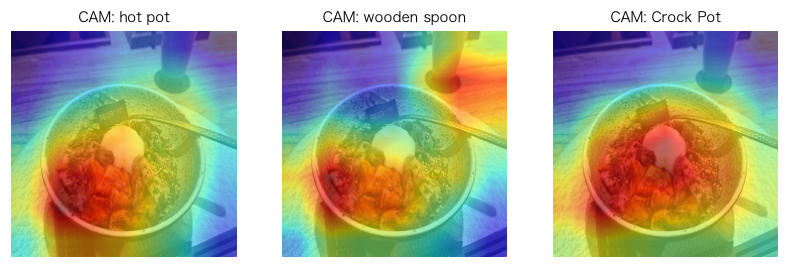

In [13]:
prob = logits.softmax(-1)[0].cpu()  # 1000 类的概率
top = prob.topk(5)  # 取前 5
cats = weights.meta["categories"]  # 类别名（英文）
for p, i in zip(top.values, top.indices):  # 打印前 5
    print(f"{p:6.1%}  {cats[i]}")  # 概率和类名
feat = cache["layer4"][0]  # [512,7,7]
fig, axes = plt.subplots(1, 3, figsize=(9, 3))  # 前 3 类各画一张
for ax, i in zip(axes, top.indices[:3]):  # 遍历
    cam = torch.einsum("c,chw->hw", resnet.fc.weight[i].detach().cpu(), feat)  # 每个位置的贡献：权重和特征逐通道相乘再求和
    overlay(load_photo().resize((224, 224)), F.relu(cam), ax=ax, title=f"CAM: {cats[i]}")  # 叠到图上
plt.show()  # 显示

> ImageNet 没有"牛肉饭"这种类别，所以它会给出最接近的类，这里只用来演示 CAM。

## 5. 从 CNN 到 ViT

CNN 的两个特点：
- **局部**：每个卷积只看 3×3 邻域，要叠很多层才能"看到"整张图（感受野逐层变大）
- **平移共享**：同一个卷积核在所有位置复用

ViT 的做法：
1. 用一个 **16×16、stride=16 的卷积**把图片切成不重叠的块，每块变成一个向量。这是 ViT 里**唯一**的卷积
2. 之后全部用**注意力**，第一层起每个块就能直接和所有块交换信息

用本章手写的 `my_conv2d` 演示：kernel=stride=16 时，`unfold` 出来的窗口正好就是互不重叠的 patch。

kernel=stride=16 的 unfold: (1, 768, 1024) → 32×32=1024 个 patch，每个 768 维
✅ patch 卷积 = 切块 + 矩阵乘法: 形状 (1, 768, 32, 32)，最大误差 0.00e+00（容差 1e-04）


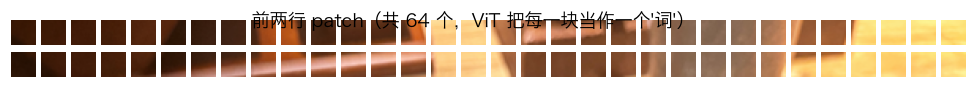

In [14]:
img512 = torch.from_numpy(np.asarray(load_photo().resize((512, 512))).copy()).permute(2, 0, 1).float()[None] / 255  # [1,3,512,512]，SmolVLM 的输入尺寸
cols = F.unfold(img512, kernel_size=16, stride=16)  # 每个 16×16 块拉直成 3×16×16=768 维
print("kernel=stride=16 的 unfold:", tuple(cols.shape), "→ 32×32=1024 个 patch，每个 768 维")  # [1,768,1024]
w_vit = torch.randn(768, 3, 16, 16) * 0.02  # 假设的 patch embedding 卷积核：768 个输出通道
check_close("patch 卷积 = 切块 + 矩阵乘法", my_conv2d(img512, w_vit, stride=16), F.conv2d(img512, w_vit, stride=16), atol=1e-4)  # 二者一致
patches = cols[0].T.reshape(-1, 3, 16, 16)  # [1024,3,16,16]：拆回小块
show_images(list(patches[:32 * 2]), cols=32, size=0.35, suptitle="前两行 patch（共 64 个，ViT 把每一块当作一个'词'）")  # 显示前两行

**下一章**：SmolVLM 的处理器如何把一张任意尺寸的照片变成模型的输入（缩放、切图、归一化、插入图像 token）。